# Additional properties of the 9-mer mutational landscape.

In [1]:
import pandas as pd
import numpy as np
import tqdm

from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LinearSegmentedColormap, Normalize

import seaborn as sn

from scripts.functions import mutation_matrix as mm
from scripts.functions import plotting as plo
from scripts.functions.colors import shm_colors
color_red = shm_colors['color_red']
color_blue = shm_colors['color_blue']
color_violet = shm_colors['color_violet']
color_gray = shm_colors['color_gray']

muts = pd.read_csv('data/Spisak_mutabilities_context.tsv', sep ="\t")

l_seq = 9
l_context = 2
sequences = mm.generate_all_sequences(l_seq)
mutation_matrix_sp = mm.compute_mutmatrix(sequences, muts, l_seq, l_context)
sequence_to_index = {seq: idx for idx, seq in enumerate(sequences)}

conn_dict_kmer = mm.connectivity(sequences)

# k-mers
right_eigvals_real, stat_freq_norm, v1, v2 = mm.k_eigenvectors_phased(10, mutation_matrix_sp, sequences)
## rotate v2 so CCCCTGGGG lies on the positive imaginary axis
target_seq = 'CCCCTGGGG'
target_idx = np.where(np.asarray(sequences) == target_seq)[0][0]
z = v2[target_idx]
if np.isclose(np.abs(z), 0):
    raise ValueError(f"{target_seq} is too close to the origin to define a rotation.")
## desired angle = 0 degrees = positive imaginary axis
target_angle = 0.0
## rotation angle
theta = target_angle - np.angle(z)
## rotate the entire complex eigenvector
v2 = v2 * np.exp(1j * theta)

100%|██████████| 589824/589824 [00:01<00:00, 487904.58it/s]


In [2]:
## creating a dataframe with all the data
kmers_df = pd.DataFrame(columns = ['seq_id', 'sequence', 'log stat freq', 'v1.real', 'v2.real', 'v2.imag', 'hs', 'cs'])
kmers_df['seq_id'] = list(range(len(sequences)))
kmers_df['sequence'] = sequences
kmers_df['log stat freq'] = np.log(stat_freq_norm.real)
kmers_df['v1.real'] = v1.real
kmers_df['v2.real'] = v2.real
kmers_df['v2.imag'] = v2.imag
kmers_df['subs_rate'] = -mutation_matrix_sp.diagonal()

### jittered colors
all_dots = plo.normal_palette(color_gray,  n=len(kmers_df), sigma_h=0, sigma_s=0, sigma_v=0.025, seed=123)
### adding colors to the dataframe
kmers_df['color'] = all_dots

## colormap for substitution rate
custom_cmap = LinearSegmentedColormap.from_list("my_cmap", [color_blue, color_red])
norm = Normalize(vmin=kmers_df['subs_rate'].min(), vmax=kmers_df['subs_rate'].max())
vals = kmers_df['subs_rate'].to_numpy()
rgba = custom_cmap(norm(vals))
kmers_df['subs_color'] = list(map(tuple, rgba))
kmers_df['color'] = all_dots

## rotations
### distance to the origin
kmers_df['radius'] = np.hypot(kmers_df['v2.real'], kmers_df['v2.imag'])
### angle in radians
kmers_df['angle'] = np.arctan2(kmers_df['v2.imag'], kmers_df['v2.real'])
### angle in degrees
kmers_df['angle_deg'] = np.degrees(kmers_df['angle']) % 360
eps = 1e-12
kmers_df.loc[kmers_df['radius'] < eps, ['angle', 'angle_deg']] = np.nan

 ## a: Relationship between the substitution rate and log stationary frequencies of 9-mers (colored by substitution rate: red = high, blue = low).

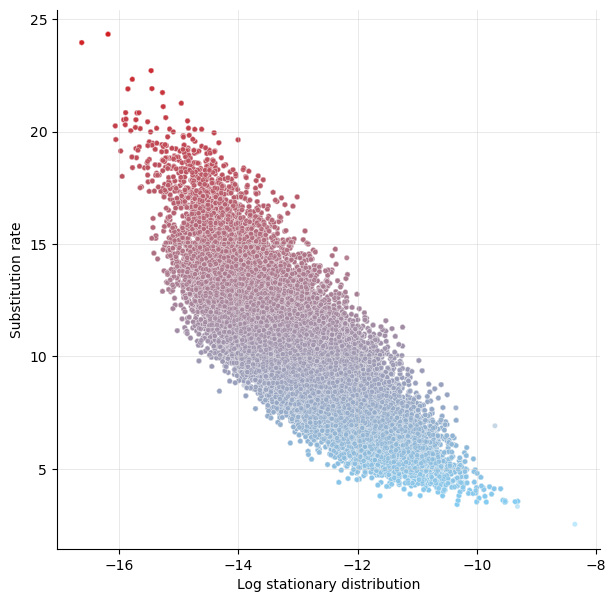

In [3]:
fig, axes = plt.subplots(1, 1, figsize=(7, 7))
kmers_df_sorted = kmers_df.sort_values(by = 'v2.imag', ascending=False).reset_index(drop = True)
axes.scatter(x = kmers_df_sorted['log stat freq'], y = kmers_df_sorted['subs_rate'], c = kmers_df_sorted['subs_color'], s = 14, edgecolor = 'white', linewidth=0.3, alpha = 0.5, rasterized = True)
plt.xlabel('Log stationary distribution')
plt.ylabel('Substitution rate')
axes.grid(True, alpha=0.6, color = '#CCCCCC')

sn.despine()

## b: Comparison of log stationary frequencies for 9-mers that are reverse complements of each other.

In [4]:
kmer_values = kmers_df_sorted.set_index("sequence")[["log stat freq", "v1.real"]]
complement = str.maketrans("ACGT", "TGCA")
complement_result = {}
processed_sequences = []

for seq in tqdm.tqdm(sequences):
    if seq in processed_sequences:
        continue

    revcomp = seq.translate(complement)[::-1]
    processed_sequences.append(revcomp)

    base_vals = kmer_values.loc[seq].to_numpy(dtype=float)
    revcomp_vals = kmer_values.loc[revcomp].to_numpy(dtype=float)

    complement_result[seq] = [base_vals[0], base_vals[1],
                              revcomp_vals[0], revcomp_vals[1]]
complement_result = pd.DataFrame(complement_result).T.reset_index()
complement_result.columns = ['sequence', 'log stat freq', 'v1.real', 'reverse log stat freq', 'reverse v1.real']

100%|██████████| 262144/262144 [02:53<00:00, 1515.01it/s]


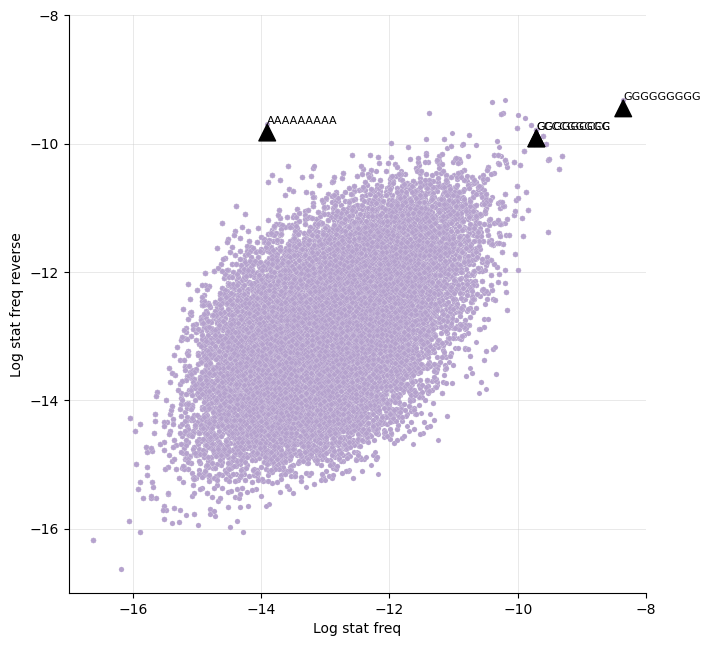

In [5]:
fig, axes = plt.subplots(1, 1, figsize=(7.5, 7.5))

to_annotate = ['CCCCGGGGG', 'GGGGCCCCC', 'CCCCCGGGG', 'GGGGGCCCC',
               ['A']*l_seq, ['T']*l_seq, ['G']*l_seq, ['C']*l_seq]

axes.scatter(data = complement_result, x = 'log stat freq', y = 'reverse log stat freq', s=14, alpha = 1, edgecolor = 'white', linewidth = 0.1, zorder = 2, rasterized = True, c = color_violet)

for item in to_annotate:
    item = ''.join(item)
    try:
        coords_x = complement_result['log stat freq'][complement_result['sequence'] == item].iloc[0]
        coords_y = complement_result['reverse log stat freq'][complement_result['sequence'] == item].iloc[0]
        axes.annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                     arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                     fontsize=8, color='black')
    except IndexError:
        continue

axes.set_xlabel('Log stat freq')
axes.set_ylabel('Log stat freq reverse')
axes.set_xlim(-17, -8)
axes.set_ylim(-17, -8)
axes.xaxis.set_major_locator(MultipleLocator(2))
axes.yaxis.set_major_locator(MultipleLocator(2))
axes.set_aspect('equal', adjustable='box')
axes.grid(True, alpha=0.6, color = '#CCCCCC')

sn.despine()

## c: Characteristic decay times ($\tau_k = \frac{-1}{\operatorname{Re}(\lambda_k)}$) of deviations from stationarity plotted against eigenspace index ($k$). Numbers indicate the corresponding oscillation periods for complex eigenvalues.

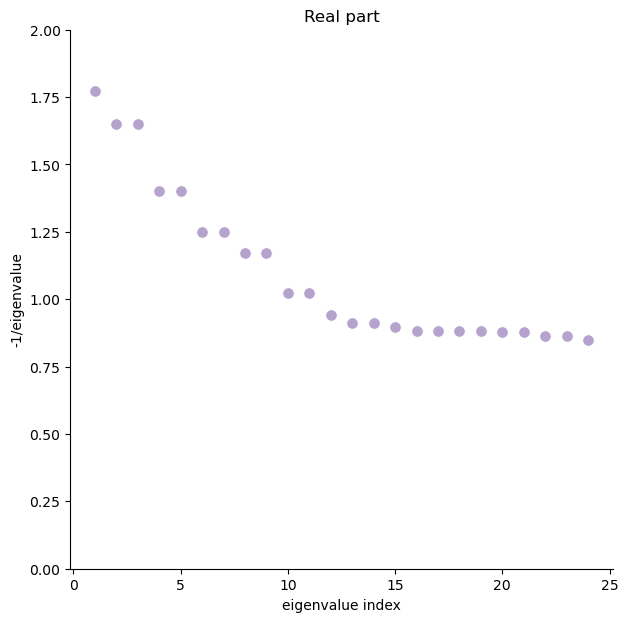

In [6]:
k = 25
right_eigvals, stat_freq_norm, v1, v2 = mm.k_eigenvectors_phased(k, mutation_matrix_sp, sequences)
## rotate v2 so CCCCTGGGG lies on the positive imaginary axis
target_seq = 'CCCCTGGGG'
target_idx = np.where(np.asarray(sequences) == target_seq)[0][0]
z = v2[target_idx]
if np.isclose(np.abs(z), 0):
    raise ValueError(f"{target_seq} is too close to the origin to define a rotation.")
## desired angle = 90 degrees = positive imaginary axis
target_angle = np.pi / 2
## rotation angle
theta = target_angle - np.angle(z)
## rotate the entire complex eigenvector
v2 = v2 * np.exp(1j * theta)
right_eigvals_real = right_eigvals.real[1:]

fig, axes = plt.subplots(1, 1, figsize=(7, 7))

k_values = np.arange(1, len(right_eigvals_real) + 1)
sn.scatterplot(x = k_values, y =  -1/right_eigvals_real, color = color_violet, s = 70, ax = axes)
plt.ylim(0, 2)
plt.title('Real part')
plt.xlabel('eigenvalue index')
plt.ylabel('-1/eigenvalue')

sn.despine()

In [7]:
for lam in right_eigvals[1:]:
    ### decay time
    decay = -1/lam.real
    ## angle per decay time
    angle_pd = np.abs(lam.imag) * decay
    period = 2 * np.pi / np.abs(lam.imag)
    print(lam, f'period = {period}, decay = {decay}, angle per decay time = {angle_pd}')

(-0.5642463515356804+0j) period = inf, decay = 1.772275526954408, angle per decay time = 0.0
(-0.6058714056826192+0.002083286078582769j) period = 3015.9973571435526, decay = 1.6505152588829086, angle per decay time = 0.0034384954613191983
(-0.6058714056826192-0.002083286078582769j) period = 3015.9973571435526, decay = 1.6505152588829086, angle per decay time = 0.0034384954613191983
(-0.713473438307661+0.002345333084460333j) period = 2679.016191265371, decay = 1.4015938734481441, angle per decay time = 0.0032872044823748416
(-0.713473438307661-0.002345333084460333j) period = 2679.016191265371, decay = 1.4015938734481441, angle per decay time = 0.0032872044823748416
(-0.8008261921362319+0.005396065848969067j) period = 1164.4011550340895, decay = 1.2487104066020431, angle per decay time = 0.006738123580317563
(-0.8008261921362319-0.005396065848969067j) period = 1164.4011550340895, decay = 1.2487104066020431, angle per decay time = 0.006738123580317563
(-0.8548195088043581+0.00053725607475

/var/folders/bb/6j1bt4dj4x15t9jtm7vlh6gh0000gp/T/ipykernel_73187/1198384419.py:6: RuntimeWarning: divide by zero encountered in scalar divide
  period = 2 * np.pi / np.abs(lam.imag)


## d: Distance from the origin in plot with 9mers (c) plotted against diffusion axis 1.

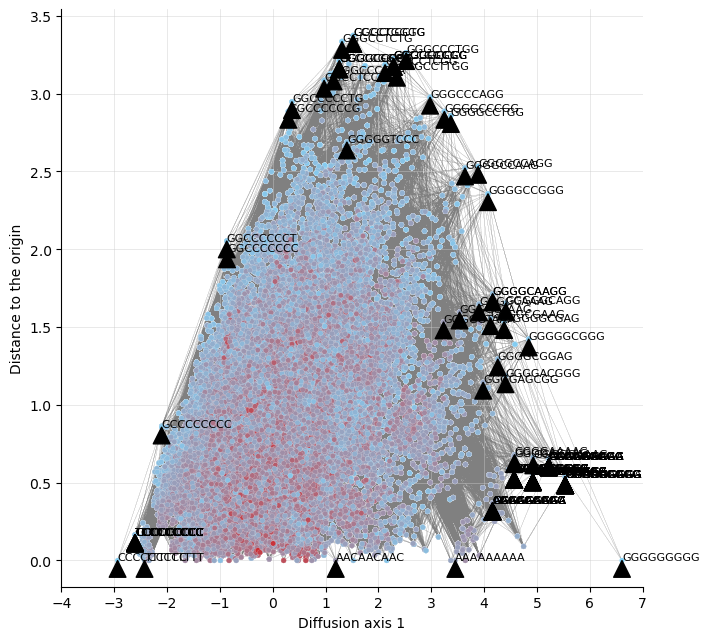

In [8]:
kmers_df_sorted = kmers_df.sort_values(by = 'angle_deg').reset_index(drop = True)

fig, axes = plt.subplots(1, 1, figsize=(7.5, 7.5))

to_annotate = ['CCCCGGGGG', 'GGGGCCCCC', 'CCCCCGGGG', 'GGGGGCCCC', 'CCCCTGGGG',
               ['A']*l_seq, ['T']*l_seq, ['G']*l_seq, ['C']*l_seq]
to_annotate = (to_annotate +
               ['GGGCCCTGG', 'GGGCCCCGG', 'GGGCCTCGG', 'GGGCCTTGG', 'GGGCCCCTG', 'GGGCCTCTG', 'GGGCCCCCG',
                'GGGCCCCCA', 'GGCCTCCAG', 'GGCCCCCTG', 'GGCCCCCCG', 'GGCCCCCCT', 'GGCCCCCCC', 'GCCCCCCCC',
                'TCCCCCCCC', 'AACAACAAC', 'GGGGGGAGG', 'GGGGGAAGG', 'GGGGGAAAG', 'GGGGAAAAG', 'GGGGAGAAG',
                'GGGGGAGAG', 'GGGGACGGG', 'GGGGAGCGG', 'GGGGCGGAG', 'GGGGGCGGG', 'GGGGGTCCC', 'GGGGGCGAG',
                'GGGGCGAAG', 'GGGGGCAGG', 'GGGGCAAGG', 'GGGGCAAGG', 'GGGGCAAAG', 'GGGGGTAAG', 'GGGGGTAAA',
                'GGGGCCGGG', 'GGGGCCAGG', 'GGGGCCAAG', 'GGGGCCTGG', 'GGGGCCCGG', 'GGGCCCAGG'])
to_annotate = (to_annotate +
               ['GGAGGGGGG', 'GAGGGGGGG', 'AGGGGGGGG', 'GGGGGGGGA', 'GGGGGGGAG', 'GGGGGGAGG', 'GGGGGAGGG',
                'GGGGAGGGG', 'GGGAGGGGG',
                'GGAAGGGGG', 'GAAGGGGGG', 'AAGGGGGGG', 'AGGGGGGGA', 'GGGGGGGAA', 'GGGGGGAAG', 'GGGGGAAGG',
                'GGGGAAGGG', 'GGGAAGGGG',
                'GAGAGGGGG', 'AGAGGGGGG', 'GAGGGGGGA', 'AGGGGGGAG', 'GGGGGGAGA', 'GGGGGAGAG', 'GGGGAGAGG',
                'GGGAGAGGG', 'GGAGAGGGG',
                'CCCCCCCCT', 'CCCCCCCTC', 'CCCCCCTCC', 'CCCCCTCCC', 'CCCCTCCCC', 'CCCTCCCCC', 'CCTCCCCCC',
                'CTCCCCCCC', 'TCCCCCCCC',
                'GAGGAGGGG', 'AGGAGGGGG', 'GGAGGGGGA', 'GAGGGGGAG', 'AGGGGGAGG', 'GGGGGAGGA', 'GGGGAGGAG',
                'GGGAGGAGG', 'GGAGGAGGG',
                'AGGAGAGGG', 'GGAGAGGGA', 'GAGAGGGAG', 'AGAGGGAGG', 'GAGGGAGGA', 'AGGGAGGAG', 'GGGAGGAGA',
                'GGAGGAGAG', 'GAGGAGAGG'
                ])

## distance to the origin
vis_x = 'v1.real'
vis_y = 'radius'
axes.scatter(data = kmers_df_sorted, x = vis_x, y = vis_y, s=14, c = 'subs_color', alpha = 1, edgecolor = 'white', linewidth = 0.1, zorder = 2, rasterized = True)

### edges underneath
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(), ax=axes, color="gray", linewidth=0.2, alpha=0.1)

for item in to_annotate:
    item = ''.join(item)
    coords_x = kmers_df_sorted[vis_x][kmers_df_sorted['sequence'] == item].iloc[0]
    coords_y = kmers_df_sorted[vis_y][kmers_df_sorted['sequence'] == item].iloc[0]
    axes.annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                 arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                 fontsize=8, color='black')
axes.set_xlabel('Diffusion axis 1')
axes.set_ylabel('Distance to the origin')
axes.set_xlim(-4, 7)
axes.xaxis.set_major_locator(MultipleLocator(1))
axes.grid(True, alpha=0.6, color = '#CCCCCC')

sn.despine()

## e: Angular coordinate from plot with 9mers (c) plotted against the diffusion axis 1, showing one segment of angular range (40$^\circ$) or the full range (360$^\circ$).

100%|██████████| 134108/134108 [00:00<00:00, 1261170.75it/s]


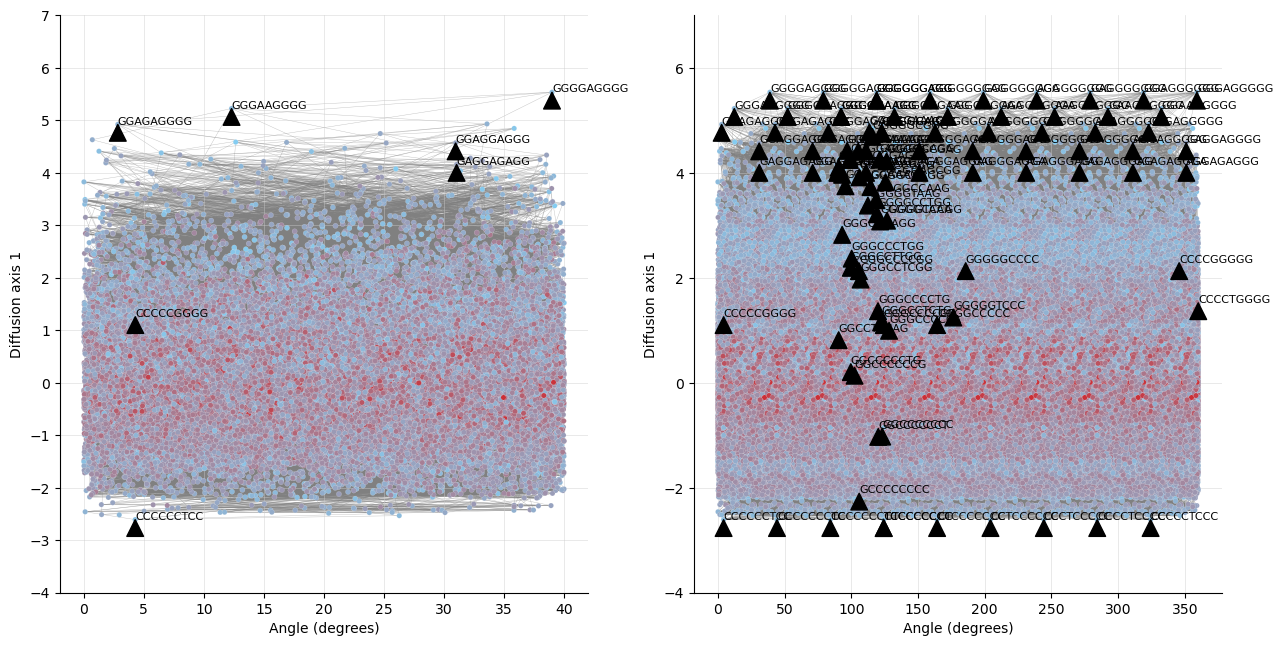

In [9]:
kmers_df_sorted = kmers_df.sort_values(by = 'angle_deg').reset_index(drop = True)

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

to_annotate = ['CCCCGGGGG', 'GGGGCCCCC', 'CCCCCGGGG', 'GGGGGCCCC', 'CCCCTGGGG',
               ['A']*l_seq, ['T']*l_seq, ['G']*l_seq, ['C']*l_seq]
to_annotate = (to_annotate +
               ['GGGCCCTGG', 'GGGCCCCGG', 'GGGCCTCGG', 'GGGCCTTGG', 'GGGCCCCTG', 'GGGCCTCTG', 'GGGCCCCCG',
                'GGGCCCCCA', 'GGCCTCCAG', 'GGCCCCCTG', 'GGCCCCCCG', 'GGCCCCCCT', 'GGCCCCCCC', 'GCCCCCCCC',
                'TCCCCCCCC', 'AACAACAAC', 'GGGGGGAGG', 'GGGGGAAGG', 'GGGGGAAAG', 'GGGGAAAAG', 'GGGGAGAAG',
                'GGGGGAGAG', 'GGGGACGGG', 'GGGGAGCGG', 'GGGGCGGAG', 'GGGGGCGGG', 'GGGGGTCCC', 'GGGGGCGAG',
                'GGGGCGAAG', 'GGGGGCAGG', 'GGGGCAAGG', 'GGGGCAAGG', 'GGGGCAAAG', 'GGGGGTAAG', 'GGGGGTAAA',
                'GGGGCCGGG', 'GGGGCCAGG', 'GGGGCCAAG', 'GGGGCCTGG', 'GGGGCCCGG', 'GGGCCCAGG'])
to_annotate = (to_annotate +
               ['GGAGGGGGG', 'GAGGGGGGG', 'AGGGGGGGG', 'GGGGGGGGA', 'GGGGGGGAG', 'GGGGGGAGG', 'GGGGGAGGG',
                'GGGGAGGGG', 'GGGAGGGGG',
                'GGAAGGGGG', 'GAAGGGGGG', 'AAGGGGGGG', 'AGGGGGGGA', 'GGGGGGGAA', 'GGGGGGAAG', 'GGGGGAAGG',
                'GGGGAAGGG', 'GGGAAGGGG',
                'GAGAGGGGG', 'AGAGGGGGG', 'GAGGGGGGA', 'AGGGGGGAG', 'GGGGGGAGA', 'GGGGGAGAG', 'GGGGAGAGG',
                'GGGAGAGGG', 'GGAGAGGGG',
                'CCCCCCCCT', 'CCCCCCCTC', 'CCCCCCTCC', 'CCCCCTCCC', 'CCCCTCCCC', 'CCCTCCCCC', 'CCTCCCCCC',
                'CTCCCCCCC', 'TCCCCCCCC',
                'GAGGAGGGG', 'AGGAGGGGG', 'GGAGGGGGA', 'GAGGGGGAG', 'AGGGGGAGG', 'GGGGGAGGA', 'GGGGAGGAG',
                'GGGAGGAGG', 'GGAGGAGGG',
                'AGGAGAGGG', 'GGAGAGGGA', 'GAGAGGGAG', 'AGAGGGAGG', 'GAGGGAGGA', 'AGGGAGGAG', 'GGGAGGAGA',
                'GGAGGAGAG', 'GAGGAGAGG'
                ])

## angle 40 degrees
kmers_df_sorted = kmers_df_sorted.sort_values(by = 'radius', ascending = False).reset_index(drop = True)
kmers_df_subset = kmers_df[kmers_df['angle_deg'] < 40]
kmers_df_sorted_subset = kmers_df_sorted[kmers_df_sorted['angle_deg'] < 40]

conn_dict_kmer_subset = mm.connectivity(kmers_df_subset['sequence'].unique())

vis_x = 'angle_deg'
vis_y = 'v1.real'

axes[0].scatter(data = kmers_df_sorted_subset, x = vis_x, y = vis_y, s=14, c = 'subs_color', alpha = 1, edgecolor = 'white', linewidth = 0.1, zorder = 2, rasterized = True)

### edges underneath
plo.add_edges(conn_dict_kmer_subset, kmers_df_subset[vis_x].to_numpy(), kmers_df_subset[vis_y].to_numpy(),
              ax=axes[0], color="gray", linewidth=0.3, alpha=0.5)

for item in to_annotate:
    item = ''.join(item)
    try:
        coords_x = kmers_df_sorted_subset[vis_x][kmers_df_sorted_subset['sequence'] == item].iloc[0]
        coords_y = kmers_df_sorted_subset[vis_y][kmers_df_sorted_subset['sequence'] == item].iloc[0]
        axes[0].annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                     arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                     fontsize=8, color='black')
    except IndexError:
        continue
axes[0].set_xlabel('Angle (degrees)')
axes[0].set_ylabel('Diffusion axis 1')
axes[0].set_ylim(-4, 7)
axes[0].yaxis.set_major_locator(MultipleLocator(1))

## angle full range
kmers_df_sorted = kmers_df_sorted.sort_values(by = 'radius', ascending = False).reset_index(drop = True)
vis_x = 'angle_deg'
vis_y = 'v1.real'

axes[1].scatter(data = kmers_df_sorted, x = vis_x, y = vis_y, s=14, c = 'subs_color', alpha = 1, edgecolor = 'white', linewidth = 0.1, zorder = 2, rasterized = True)

### edges underneath
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[1], color="gray", linewidth=0.3, alpha=0.5)

for item in to_annotate:
    item = ''.join(item)
    coords_x = kmers_df_sorted[vis_x][kmers_df_sorted['sequence'] == item].iloc[0]
    coords_y = kmers_df_sorted[vis_y][kmers_df_sorted['sequence'] == item].iloc[0]
    axes[1].annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                 arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                 fontsize=8, color='black')
axes[1].set_xlabel('Angle (degrees)')
axes[1].set_ylabel('Diffusion axis 1')
axes[1].set_ylim(-4, 7)
axes[1].yaxis.set_major_locator(MultipleLocator(2))

for ax in axes:
    ax.grid(True, alpha=0.6, color = '#CCCCCC')

sn.despine()